# Dust attenuation

`galform_analysis.dust` applies the **diffuse-dust** part of GALFORM's dust model to the intrinsic luminosities in `galaxies.hdf5`. It is a port of GALFORM's own code: dust lives in the gas disk, with central face-on optical depth `tau_V0 = C_V Z_cold Sigma_gas0`. The attenuation of disk and bulge light comes from the Ferrara et al. (1999) radiative-transfer tables, and depends on wavelength, inclination and bulge/disk size. A fraction `fcloud` of the gas is in molecular clouds rather than diffuse, and ongoing bursts carry their own dust.

`dust='lacey16'` uses the Lacey et al. (2016) parameters (`fcloud = 0.5`, MW dust, `h_z/h = 1`). It reproduces GALFORM's attenuated magnitudes to < 1e-5 mag. The extra attenuation of stars younger than 1 Myr inside molecular clouds is **not** included: it needs GALFORM's `neta` tables, which are not written to `galaxies.hdf5`. It matters mainly in the far-UV.

The attenuation tables ship with GALFORM: set `GALFORM_DATA_DIR` to GALFORM's `Data` directory.

In [1]:
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

import galform_analysis
from galform_analysis import get_base_dir

mpl.setconfig()

# Configure once per session:
# galform_analysis.set_base_dir('/cosma5/data/durham/<user>/Galform_Out/L800/model')
# os.environ['GALFORM_DATA_DIR'] = '/path/to/galform/Data'
BASE_DIR = str(get_base_dir())
print('dust tables from', os.environ.get('GALFORM_DATA_DIR'))

dust tables from /cosma/apps/durham/dc-hick2/galform/Data


## Per-galaxy attenuation

`read_band_magnitudes` returns every galaxy's magnitude, with or without dust. With `inclination='random'` (the default) each galaxy gets an isotropic random orientation, seeded per subvolume. The same galaxy has the same orientation in every band, so colours are consistent.

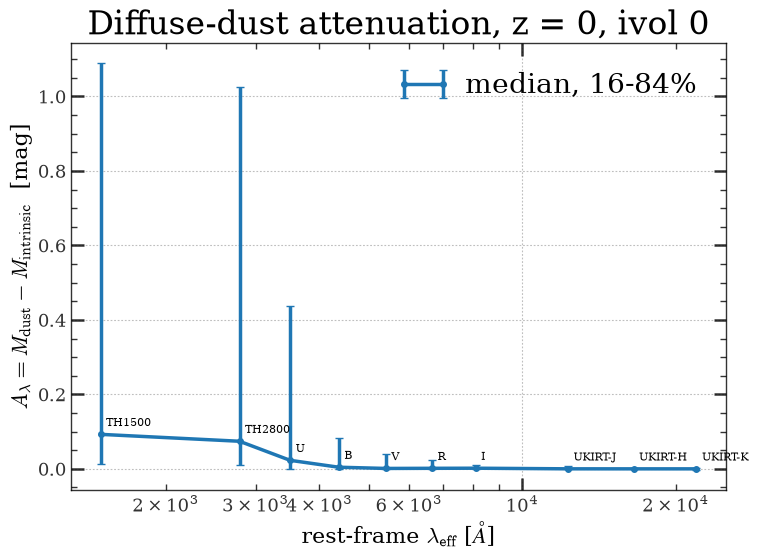

In [2]:
from galform_analysis import read_band_magnitudes

iz_path = os.path.join(BASE_DIR, 'iz271')
BANDS = ['TH1500', 'TH2800', 'U', 'B', 'V', 'R', 'I', 'UKIRT-J', 'UKIRT-H', 'UKIRT-K']
table = galform_analysis.list_bands(iz_path)

lam, median, lo, hi = [], [], [], []
for band in BANDS:
    bare = read_band_magnitudes(iz_path, 0, band)
    dusty = read_band_magnitudes(iz_path, 0, band, dust='lacey16')
    bright = bare['mag'] < -18          # galaxies with M - 5log h < -18
    a = (dusty['mag'] - bare['mag'])[bright]
    lam.append(table['lambda_eff'][bare['band_index'] - 1])
    p16, p50, p84 = np.percentile(a, [16, 50, 84])
    median.append(p50); lo.append(p50 - p16); hi.append(p84 - p50)

fig, ax = plt.subplots()
ax.errorbar(lam, median, yerr=[lo, hi], fmt='o-', ms=4, capsize=3,
            label='median, 16-84%')
for x, y, band in zip(lam, median, BANDS):
    ax.annotate(band, (x, y), textcoords='offset points', xytext=(4, 6), fontsize=8)
ax.set_xscale('log')
ax.set_xlabel(r'rest-frame $\lambda_{\rm eff}$ [$\AA$]')
ax.set_ylabel(r'$A_\lambda = M_{\rm dust} - M_{\rm intrinsic}$  [mag]')
ax.set_title('Diffuse-dust attenuation, z = 0, ivol 0')
ax.legend()
fig.tight_layout()
plt.show()

## Inclination

Edge-on disks are attenuated most. `inclination` can be `'random'`, `'face-on'`, `'average'` (the isotropic mean attenuation, as GALFORM uses for dust emission) or an angle in degrees.

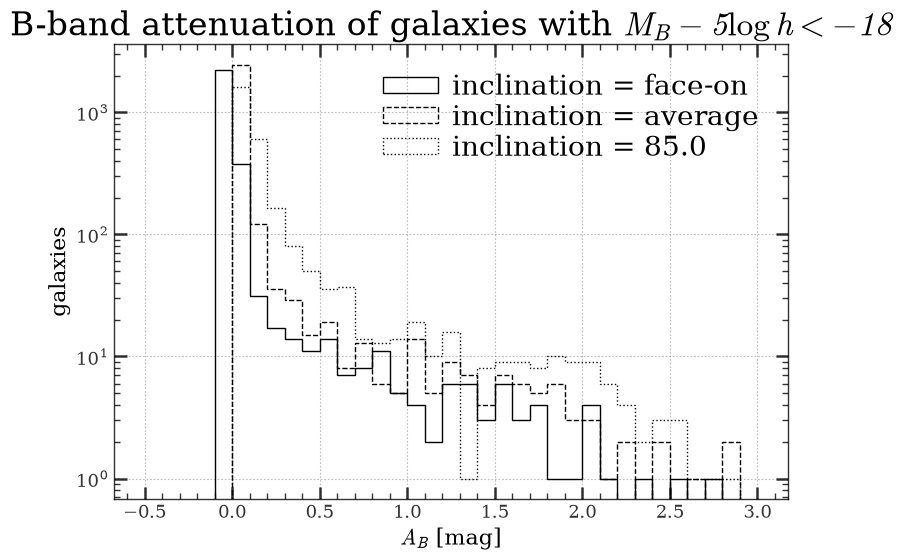

In [3]:
fig, ax = plt.subplots()
bare = read_band_magnitudes(iz_path, 0, 'B')['mag']
bright = bare < -18
bins = np.linspace(-0.5, 3.0, 36)
for inc, style in (('face-on', '-'), ('average', '--'), (85.0, ':')):
    a = read_band_magnitudes(iz_path, 0, 'B', dust='lacey16', inclination=inc)['mag'] - bare
    ax.hist(a[bright], bins=bins, histtype='step', ls=style, color='k',
            label=f'inclination = {inc}')
ax.set_yscale('log')
ax.set_xlabel(r'$A_B$ [mag]')
ax.set_ylabel('galaxies')
ax.set_title(r'B-band attenuation of galaxies with $M_B - 5\log h < -18$')
ax.legend()
fig.tight_layout()
plt.show()

## Luminosity functions with dust

Every luminosity-function function takes `dust=`, `inclination=` and `seed=`. Dust matters most in blue bands: compare bJ with 2dFGRS (Norberg et al. 2002) and K with 2MASS (Cole et al. 2001), both Schechter fits in Vega magnitudes, drawn over the magnitude ranges they were fitted to.

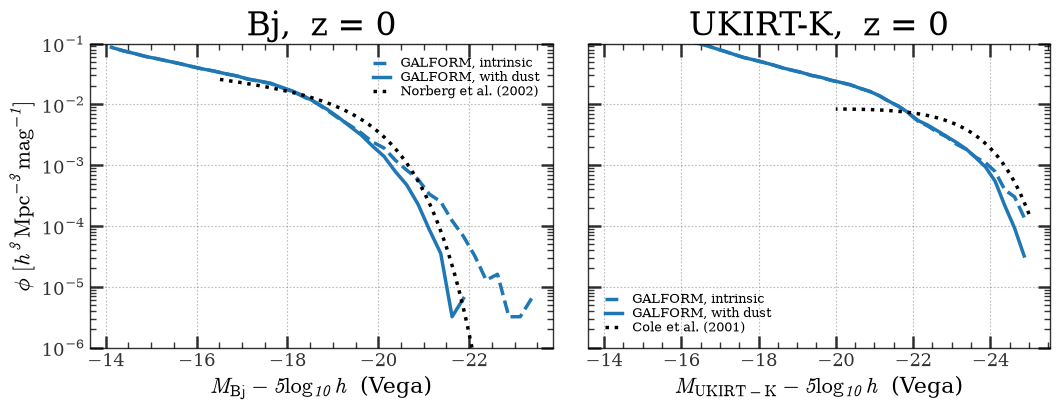

In [4]:
from galform_analysis.analysis.luminosity_functions import (
    avg_lf_given_redshift_and_subvolumes,
    schechter_magnitude,
)

IVOLS = list(range(8))
OBSERVED = {   # band: (phi*, M* - 5log h, alpha, fitted range, reference)
    'Bj': (1.61e-2, -19.66, -1.21, (-22.5, -16.5), 'Norberg et al. (2002)'),
    'UKIRT-K': (1.08e-2, -23.44, -0.96, (-25.0, -20.0), 'Cole et al. (2001)'),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (band, (phi_star, m_star, alpha, (m_lo, m_hi), ref)) in zip(
        axes, OBSERVED.items()):
    for dust, style in ((None, 'C0--'), ('lacey16', 'C0-')):
        r = avg_lf_given_redshift_and_subvolumes(271, IVOLS, band, system='Vega',
                                                 dust=dust, base_dir=BASE_DIR)
        ok = r['phi'] > 0   # empty bins cannot be drawn on a log axis
        label = 'GALFORM, intrinsic' if dust is None else 'GALFORM, with dust'
        ax.plot(r['centers'][ok], r['phi'][ok], style, label=label)
    M = np.linspace(m_lo, m_hi, 200)
    ax.plot(M, schechter_magnitude(M, phi_star, m_star, alpha), 'k:', label=ref)
    ax.set_yscale('log')
    ax.set_ylim(1e-6, 1e-1)
    ax.invert_xaxis()
    ax.set_xlabel(rf'$M_{{\rm {band}}} - 5\log_{{10}}h$  (Vega)')
    ax.set_title(f'{band},  z = 0')
    ax.legend(fontsize=9)
axes[0].set_ylabel(r'$\phi\;[h^3\,\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$')
fig.tight_layout()
plt.show()

## Other dust models

`'baugh05'` uses `fcloud = 0.25`. For other parameters build a `DustModel`; `table` can also be a path to any GALFORM `dust_*.dat` file.

In [5]:
import dataclasses
from galform_analysis.dust import DUST_MODELS, LACEY16

print(DUST_MODELS)
no_bursts = dataclasses.replace(LACEY16, name='lacey16-nobursts', rfacburst=0.0)
r = avg_lf_given_redshift_and_subvolumes(271, [0], 'Bj', dust=no_bursts, base_dir=BASE_DIR)
print(r['dust'], r['n_used'])

{'lacey16': DustModel(name='lacey16', table='dust_MW_hz1.0.dat', fcloud=0.5, rfacburst=1.0), 'baugh05': DustModel(name='baugh05', table='dust_MW_hz1.0.dat', fcloud=0.25, rfacburst=1.0)}
lacey16-nobursts 1
